# Lỗ hổng đang bị khai thác và ngưỡng CVSS 8,0

**Nhóm 14, học phần Chính sách và Quản trị an ninh mạng**

Bài báo *Automated Exploit Generation: LLMs Cross the Threshold* của Cloud Security Alliance (CSA) khuyến nghị **vá trong 48 giờ mọi lỗ hổng có điểm CVSS từ 8,0 trở lên**. Notebook này kiểm tra khuyến nghị đó bằng dữ liệu thực tế:

- Trong các lỗ hổng **đã bị khai thác thực tế**, ngưỡng 8,0 bắt được bao nhiêu, bỏ sót bao nhiêu?
- Trong các lỗ hổng **phải vá khẩn cấp** theo ngưỡng 8,0, bao nhiêu thực sự bị khai thác?

**Dữ liệu** (công khai, miễn phí):
- Điểm CVSS: tệp dữ liệu theo năm của NVD (NIST).
- Lỗ hổng đã bị khai thác: danh mục KEV của CISA (kho chính thức trên GitHub).

**Cách chạy trên Google Colab:** tải notebook lên Colab, chọn *Runtime, Run all*. Lần đầu mất vài phút để tải khoảng 300 MB dữ liệu NVD. Mọi bảng, biểu đồ và tệp Excel được lưu trong thư mục `ket_qua`.

## 1. Cấu hình và hàm dùng chung

In [1]:
import os, io, json, gzip, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

START_YEAR, END_YEAR = 2002, 2025     # tep 2002 cua NVD chua ca lo hong tu 1999 den 2002
NGUONG = 8.0                          # nguong cua khuyen nghi CSA
GIAI_DOAN = {"1999 đến 2025": (1999, 2025), "2023 đến 2025": (2023, 2025)}
DATA_DIR, OUT_DIR = "du_lieu_nvd", "ket_qua"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

NVD_FEED = "https://nvd.nist.gov/feeds/json/cve/2.0/nvdcve-2.0-{y}.json.gz"
KEV_URL = "https://raw.githubusercontent.com/cisagov/kev-data/develop/known_exploited_vulnerabilities.json"
UA = {"User-Agent": "Nhom14-course-research"}
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})

def tai(url, path):
    """Tai tep, neu da co tren may thi dung lai."""
    if os.path.exists(path):
        return open(path, "rb").read()
    data = urllib.request.urlopen(urllib.request.Request(url, headers=UA), timeout=300).read()
    open(path, "wb").write(data)
    return data

def so(x):
    """So nguyen theo kieu Viet Nam: 240.409"""
    return f"{int(x):,}".replace(",", ".")

def pct(v, k=2):
    return f"{v:.{k}f}".replace(".", ",")

def ty_le(a, b, k=2):
    """Ghi ro tu so va mau so: 877 / 1.570 = 55,86%"""
    return f"{so(a)} / {so(b)} = {pct(100 * a / b, k)}%"

BANG = {}       # luu moi bang de xuat ra Excel
SO_LIEU = {}    # luu cac so lieu chinh de viet bao cao

## 2. Tải danh mục KEV

In [2]:
kev_js = json.loads(tai(KEV_URL, os.path.join(DATA_DIR, "kev.json")))
kev = pd.DataFrame(kev_js["vulnerabilities"])
kev["cveID"] = kev["cveID"].str.upper()
SO_LIEU["kev_phien_ban"] = kev_js.get("catalogVersion")
print(f"Danh mục KEV phiên bản {kev_js.get('catalogVersion')}: {so(len(kev))} lỗ hổng")

Danh mục KEV phiên bản 2026.10.08: 1.739 lỗ hổng


## 3. Tải và đọc điểm CVSS của mọi lỗ hổng

Với mỗi lỗ hổng: lấy điểm **CVSS 3.x** nếu có, ưu tiên điểm do NVD chấm, nếu không có thì dùng điểm do đơn vị công bố chấm. Lỗ hổng cũ chỉ có CVSS 2.0 thì ghi nhận riêng. Loại lỗ hổng bị hủy (Rejected). Năm được tính theo năm trong mã CVE.

In [3]:
def chon(ds):
    if not ds:
        return None
    for m in ds:
        if m.get("type") == "Primary":
            return m
    return ds[0]

rows = []
for y in range(START_YEAR, END_YEAR + 1):
    js = json.loads(gzip.decompress(tai(NVD_FEED.format(y=y), os.path.join(DATA_DIR, f"nvdcve-2.0-{y}.json.gz"))))
    for it in js["vulnerabilities"]:
        c = it["cve"]
        if c.get("vulnStatus") == "Rejected":
            continue
        met = c.get("metrics", {})
        v3 = chon(met.get("cvssMetricV31")) or chon(met.get("cvssMetricV30"))
        v2 = chon(met.get("cvssMetricV2"))
        rows.append({"cve": c["id"].upper(), "nam": int(c["id"].split("-")[1]),
                     "cvss3": v3["cvssData"]["baseScore"] if v3 else np.nan,
                     "cvss2": v2["cvssData"]["baseScore"] if v2 else np.nan})
    print(f"Đã đọc tệp năm {y}, tổng {so(len(rows))} lỗ hổng")

df = pd.DataFrame(rows).drop_duplicates("cve")
df = df[df["nam"] <= END_YEAR].copy()
df["cvss"] = df["cvss3"].fillna(df["cvss2"])
df["phien_ban"] = np.where(df["cvss3"].notna(), "3.x", np.where(df["cvss2"].notna(), "2.0", "không có"))
df["kev"] = df["cve"].isin(set(kev["cveID"]))
co3 = df[df["phien_ban"] == "3.x"].copy()       # tap dung cho thong ke
print(f"\nXong: {so(len(df))} lỗ hổng, trong đó {so(len(co3))} có CVSS 3.x")

Đã đọc tệp năm 2002, tổng 6.670 lỗ hổng


Đã đọc tệp năm 2003, tổng 8.174 lỗ hổng


Đã đọc tệp năm 2004, tổng 10.818 lỗ hổng


Đã đọc tệp năm 2005, tổng 15.445 lỗ hổng


Đã đọc tệp năm 2006, tổng 22.440 lỗ hổng


...

Đã đọc tệp năm 2022, tổng 203.663 lỗ hổng


Đã đọc tệp năm 2023, tổng 234.327 lỗ hổng


Đã đọc tệp năm 2024, tổng 272.798 lỗ hổng


Đã đọc tệp năm 2025, tổng 316.367 lỗ hổng



Xong: 316.367 lỗ hổng, trong đó 240.409 có CVSS 3.x


## 4. Bảng 1. Tổng quan dữ liệu

In [4]:
nam_kev = kev["cveID"].str.split("-").str[1].astype(int)
b1 = pd.DataFrame([
    ["Lỗ hổng từ 1999 đến 2025, không tính lỗ hổng bị hủy", so(len(df))],
    ["Có điểm CVSS 3.x, dùng cho thống kê", ty_le(len(co3), len(df))],
    ["Chỉ có điểm CVSS 2.0", ty_le((df["phien_ban"] == "2.0").sum(), len(df))],
    ["Không có điểm CVSS", ty_le((df["phien_ban"] == "không có").sum(), len(df))],
    ["Lỗ hổng trong danh mục KEV", so(len(kev))],
    ["Lỗ hổng KEV có mã năm sau 2025, nằm ngoài phạm vi", so((nam_kev > END_YEAR).sum())],
    ["Lỗ hổng KEV thuộc phạm vi và có CVSS 3.x", so(co3["kev"].sum())],
], columns=["Hạng mục", "Giá trị"])
BANG["B1 Tong quan"] = b1
SO_LIEU["tong_quan"] = dict(tat_ca=len(df), co3=len(co3), chi_v2=int((df["phien_ban"] == "2.0").sum()),
                            khong_diem=int((df["phien_ban"] == "không có").sum()), kev_tong=len(kev),
                            kev_sau=int((nam_kev > END_YEAR).sum()), kev_co3=int(co3["kev"].sum()))
display(b1)

,Hạng mục,Giá trị
0,"Lỗ hổng từ 1999 đến 2025, không tính lỗ hổng b...",316.367
1,"Có điểm CVSS 3.x, dùng cho thống kê","240.409 / 316.367 = 75,99%"
2,Chỉ có điểm CVSS 2.0,"72.405 / 316.367 = 22,89%"
3,Không có điểm CVSS,"3.553 / 316.367 = 1,12%"
4,Lỗ hổng trong danh mục KEV,1.739
5,"Lỗ hổng KEV có mã năm sau 2025, nằm ngoài phạm vi",169
6,Lỗ hổng KEV thuộc phạm vi và có CVSS 3.x,1.570


## 5. Bảng 2 và Bảng 3. Bốn nhóm theo ngưỡng 8,0

Chia lỗ hổng theo hai câu hỏi: có thuộc diện phải vá khẩn cấp (CVSS từ 8,0) không, và có nằm trong KEV (đã bị khai thác) không. Mọi tỷ lệ đều ghi rõ tử số và mẫu số. Ô để trống là tỷ lệ không áp dụng cho nhóm đó.

In [5]:
def bon_nhom(x, nguong=NGUONG):
    N, K = len(x), int(x["kev"].sum()); KK = N - K; cao = x["cvss"] >= nguong
    a = int((cao & x["kev"]).sum()); b = int((cao & ~x["kev"]).sum())
    c = int((~cao & x["kev"]).sum()); e = int((~cao & ~x["kev"]).sum())
    return dict(N=N, K=K, KK=KK, a=a, b=b, c=c, e=e, cao=a + b, thap=c + e)

for ten, (y0, y1) in GIAI_DOAN.items():
    r = bon_nhom(co3[co3["nam"].between(y0, y1)]); SO_LIEU[ten] = r
    b2 = pd.DataFrame([
        ["CVSS từ 8,0 (phải vá khẩn cấp)", so(r["cao"]), ty_le(r["cao"], r["N"])],
        ["CVSS dưới 8,0", so(r["thap"]), ty_le(r["thap"], r["N"])],
        ["Nằm trong KEV (đã bị khai thác)", so(r["K"]), ty_le(r["K"], r["N"])],
        ["Không nằm trong KEV", so(r["KK"]), ty_le(r["KK"], r["N"])],
    ], columns=["Nhóm", "Số lượng", "So với tổng số lỗ hổng"])
    b3 = pd.DataFrame([
        ["CVSS từ 8,0, nằm trong KEV (vá đúng)", so(r["a"]), ty_le(r["a"], r["N"]), ty_le(r["a"], r["K"]), "", ty_le(r["a"], r["cao"])],
        ["CVSS từ 8,0, không nằm trong KEV", so(r["b"]), ty_le(r["b"], r["N"]), "", ty_le(r["b"], r["KK"]), ty_le(r["b"], r["cao"])],
        ["CVSS dưới 8,0, nằm trong KEV (bị bỏ sót)", so(r["c"]), ty_le(r["c"], r["N"]), ty_le(r["c"], r["K"]), "", ty_le(r["c"], r["thap"])],
        ["CVSS dưới 8,0, không nằm trong KEV", so(r["e"]), ty_le(r["e"], r["N"]), "", ty_le(r["e"], r["KK"]), ty_le(r["e"], r["thap"])],
    ], columns=["Nhóm", "Số lượng", "So với tổng số lỗ hổng", "So với nhóm KEV", "So với nhóm không KEV", "So với nhóm cùng ngưỡng"])
    BANG[f"B2 Nhom tong {y0}-{y1}"] = b2; BANG[f"B3 Bon nhom {y0}-{y1}"] = b3
    print(f"\nGIAI ĐOẠN {ten.upper()}: {so(r['N'])} lỗ hổng, {so(r['K'])} lỗ hổng KEV")
    display(b2); display(b3)


GIAI ĐOẠN 1999 ĐẾN 2025: 240.409 lỗ hổng, 1.570 lỗ hổng KEV


,Nhóm,Số lượng,So với tổng số lỗ hổng
0,"CVSS từ 8,0 (phải vá khẩn cấp)",66.722,"66.722 / 240.409 = 27,75%"
1,"CVSS dưới 8,0",173.687,"173.687 / 240.409 = 72,25%"
2,Nằm trong KEV (đã bị khai thác),1.570,"1.570 / 240.409 = 0,65%"
3,Không nằm trong KEV,238.839,"238.839 / 240.409 = 99,35%"


,Nhóm,Số lượng,So với tổng số lỗ hổng,So với nhóm KEV,So với nhóm không KEV,So với nhóm cùng ngưỡng
0,"CVSS từ 8,0, nằm trong KEV (vá đúng)",877,"877 / 240.409 = 0,36%","877 / 1.570 = 55,86%",,"877 / 66.722 = 1,31%"
1,"CVSS từ 8,0, không nằm trong KEV",65.845,"65.845 / 240.409 = 27,39%",,"65.845 / 238.839 = 27,57%","65.845 / 66.722 = 98,69%"
2,"CVSS dưới 8,0, nằm trong KEV (bị bỏ sót)",693,"693 / 240.409 = 0,29%","693 / 1.570 = 44,14%",,"693 / 173.687 = 0,40%"
3,"CVSS dưới 8,0, không nằm trong KEV",172.994,"172.994 / 240.409 = 71,96%",,"172.994 / 238.839 = 72,43%","172.994 / 173.687 = 99,60%"



GIAI ĐOẠN 2023 ĐẾN 2025: 109.597 lỗ hổng, 518 lỗ hổng KEV


,Nhóm,Số lượng,So với tổng số lỗ hổng
0,"CVSS từ 8,0 (phải vá khẩn cấp)",29.279,"29.279 / 109.597 = 26,72%"
1,"CVSS dưới 8,0",80.318,"80.318 / 109.597 = 73,28%"
2,Nằm trong KEV (đã bị khai thác),518,"518 / 109.597 = 0,47%"
3,Không nằm trong KEV,109.079,"109.079 / 109.597 = 99,53%"


,Nhóm,Số lượng,So với tổng số lỗ hổng,So với nhóm KEV,So với nhóm không KEV,So với nhóm cùng ngưỡng
0,"CVSS từ 8,0, nằm trong KEV (vá đúng)",295,"295 / 109.597 = 0,27%","295 / 518 = 56,95%",,"295 / 29.279 = 1,01%"
1,"CVSS từ 8,0, không nằm trong KEV",28.984,"28.984 / 109.597 = 26,45%",,"28.984 / 109.079 = 26,57%","28.984 / 29.279 = 98,99%"
2,"CVSS dưới 8,0, nằm trong KEV (bị bỏ sót)",223,"223 / 109.597 = 0,20%","223 / 518 = 43,05%",,"223 / 80.318 = 0,28%"
3,"CVSS dưới 8,0, không nằm trong KEV",80.095,"80.095 / 109.597 = 73,08%",,"80.095 / 109.079 = 73,43%","80.095 / 80.318 = 99,72%"


## 6. Bảng 4. Các chỉ số so sánh

In [6]:
A, B = SO_LIEU["1999 đến 2025"], SO_LIEU["2023 đến 2025"]
def dong(ten, f): return [ten, f(A), f(B)]
b4 = pd.DataFrame([
    dong("Tỷ lệ bỏ sót lỗ hổng bị khai thác", lambda r: ty_le(r["c"], r["K"])),
    dong("Tỷ lệ bị khai thác trong nhóm phải vá", lambda r: ty_le(r["a"], r["cao"])),
    dong("Tỷ lệ bị khai thác trong nhóm không ưu tiên", lambda r: ty_le(r["c"], r["thap"])),
    dong("Nhóm từ 8,0 bị khai thác nhiều hơn nhóm dưới 8,0",
         lambda r: f"{pct(100*r['a']/r['cao'])}% / {pct(100*r['c']/r['thap'])}% = {pct((r['a']/r['cao'])/(r['c']/r['thap']))} lần"),
    dong("Số lỗ hổng phải vá cho mỗi lỗ hổng bị khai thác bắt được", lambda r: f"{so(r['cao'])} / {so(r['a'])} = {pct(r['cao']/r['a'], 1)}"),
    dong("Số bị bỏ sót so với số bắt được", lambda r: ty_le(r["c"], r["a"], 1)),
], columns=["Chỉ số", "1999 đến 2025", "2023 đến 2025"])
BANG["B4 Chi so so sanh"] = b4
display(b4)

,Chỉ số,1999 đến 2025,2023 đến 2025
0,Tỷ lệ bỏ sót lỗ hổng bị khai thác,"693 / 1.570 = 44,14%","223 / 518 = 43,05%"
1,Tỷ lệ bị khai thác trong nhóm phải vá,"877 / 66.722 = 1,31%","295 / 29.279 = 1,01%"
2,Tỷ lệ bị khai thác trong nhóm không ưu tiên,"693 / 173.687 = 0,40%","223 / 80.318 = 0,28%"
3,"Nhóm từ 8,0 bị khai thác nhiều hơn nhóm dưới 8,0","1,31% / 0,40% = 3,29 lần","1,01% / 0,28% = 3,63 lần"
4,Số lỗ hổng phải vá cho mỗi lỗ hổng bị khai thá...,"66.722 / 877 = 76,1","29.279 / 295 = 99,3"
5,Số bị bỏ sót so với số bắt được,"693 / 877 = 79,0%","223 / 295 = 75,6%"


## 7. Bảng 5. Phân bố điểm CVSS: tất cả lỗ hổng so với lỗ hổng bị khai thác

Giai đoạn 1999 đến 2025. Cột cuối là xác suất một lỗ hổng trong khoảng điểm đó nằm trong KEV.

In [7]:
CAN = [0, 4, 7, 8, 9, 10.01]
NHAN = ["Dưới 4,0", "4,0 đến 6,9", "7,0 đến 7,9", "8,0 đến 8,9", "9,0 đến 10"]
co3["khoang"] = pd.cut(co3["cvss"], CAN, labels=NHAN, right=False)
N, K = len(co3), int(co3["kev"].sum())
t = co3.groupby("khoang", observed=False).agg(tat_ca=("cve", "size"), kev=("kev", "sum"))
b5 = pd.DataFrame({
    "Khoảng CVSS": NHAN,
    "Tất cả lỗ hổng": [ty_le(v, N) for v in t["tat_ca"]],
    "Lỗ hổng KEV": [ty_le(v, K) for v in t["kev"]],
    "Xác suất bị khai thác": [ty_le(k, n, 3) for k, n in zip(t["kev"], t["tat_ca"])]})
BANG["B5 Phan bo CVSS"] = b5
SO_LIEU["phan_bo"] = {nh: dict(tat_ca=int(a), kev=int(k)) for nh, a, k in zip(NHAN, t["tat_ca"], t["kev"])}
display(b5)

,Khoảng CVSS,Tất cả lỗ hổng,Lỗ hổng KEV,Xác suất bị khai thác
0,"Dưới 4,0","4.785 / 240.409 = 1,99%","5 / 1.570 = 0,32%","5 / 4.785 = 0,104%"
1,"4,0 đến 6,9","104.999 / 240.409 = 43,68%","174 / 1.570 = 11,08%","174 / 104.999 = 0,166%"
2,"7,0 đến 7,9","63.903 / 240.409 = 26,58%","514 / 1.570 = 32,74%","514 / 63.903 = 0,804%"
3,"8,0 đến 8,9","32.025 / 240.409 = 13,32%","343 / 1.570 = 21,85%","343 / 32.025 = 1,071%"
4,"9,0 đến 10","34.697 / 240.409 = 14,43%","534 / 1.570 = 34,01%","534 / 34.697 = 1,539%"


## 8. Bảng 6. So sánh các ngưỡng CVSS khác nhau (1999 đến 2025)

In [8]:
b6 = []
SO_LIEU["nguong"] = {}
for g in [7.0, 8.0, 9.0]:
    r = bon_nhom(co3, g); SO_LIEU["nguong"][g] = r
    b6.append([f"CVSS từ {pct(g, 1)}" + (" (khuyến nghị CSA)" if g == NGUONG else ""),
               ty_le(r["cao"], r["N"]), ty_le(r["a"], r["K"]), ty_le(r["c"], r["K"]), ty_le(r["a"], r["cao"])])
b6 = pd.DataFrame(b6, columns=["Quy tắc", "Phải vá khẩn cấp", "Bắt được lỗ hổng KEV", "Bỏ sót lỗ hổng KEV",
                               "Tỷ lệ bị khai thác trong nhóm phải vá"])
BANG["B6 So sanh nguong"] = b6
display(b6)

,Quy tắc,Phải vá khẩn cấp,Bắt được lỗ hổng KEV,Bỏ sót lỗ hổng KEV,Tỷ lệ bị khai thác trong nhóm phải vá
0,"CVSS từ 7,0","130.625 / 240.409 = 54,33%","1.391 / 1.570 = 88,60%","179 / 1.570 = 11,40%","1.391 / 130.625 = 1,06%"
1,"CVSS từ 8,0 (khuyến nghị CSA)","66.722 / 240.409 = 27,75%","877 / 1.570 = 55,86%","693 / 1.570 = 44,14%","877 / 66.722 = 1,31%"
2,"CVSS từ 9,0","34.697 / 240.409 = 14,43%","534 / 1.570 = 34,01%","1.036 / 1.570 = 65,99%","534 / 34.697 = 1,54%"


## 9. Bảng 7. Lỗ hổng KEV có CVSS dưới 8,0 theo từng năm

In [9]:
kv = co3[co3["kev"]]
t7 = kv.groupby("nam").agg(kev=("cve", "size"), duoi=("cvss", lambda s: int((s < NGUONG).sum())))
t7 = t7[t7.index >= 2010]
b7 = pd.DataFrame({"Năm": t7.index, "Lỗ hổng KEV": [so(v) for v in t7["kev"]],
                   "Có CVSS dưới 8,0": [ty_le(d, k, 1) for d, k in zip(t7["duoi"], t7["kev"])]})
BANG["B7 Theo nam"] = b7
SO_LIEU["theo_nam"] = {int(y): dict(kev=int(k), duoi=int(d)) for y, k, d in zip(t7.index, t7["kev"], t7["duoi"])}
display(b7)

,Năm,Lỗ hổng KEV,"Có CVSS dưới 8,0"
0,2010,23,"13 / 23 = 56,5%"
1,2011,9,"4 / 9 = 44,4%"
2,2012,22,"7 / 22 = 31,8%"
3,2013,38,"18 / 38 = 47,4%"
4,2014,34,"12 / 34 = 35,3%"
5,2015,48,"21 / 48 = 43,8%"
6,2016,60,"32 / 60 = 53,3%"
7,2017,86,"33 / 86 = 38,4%"
8,2018,89,"41 / 89 = 46,1%"
9,2019,119,"59 / 119 = 49,6%"


## 10. Bảng 8 và Bảng 9. Ai và cái gì nằm trong nhóm bị bỏ sót

In [10]:
bo_sot = (kv[kv["cvss"] < NGUONG].merge(kev[["cveID", "vendorProject", "product", "dateAdded"]],
                                         left_on="cve", right_on="cveID"))
n_bs = len(bo_sot)
nc = bo_sot["vendorProject"].value_counts().head(10)
b8 = pd.DataFrame({"Nhà cung cấp": nc.index, "Số lỗ hổng bị bỏ sót": [ty_le(v, n_bs, 1) for v in nc.values]})
vd = bo_sot.sort_values("cvss").head(15)
b9 = pd.DataFrame({"Mã CVE": vd["cve"], "CVSS": [pct(v, 1) for v in vd["cvss"]],
                   "Nhà cung cấp": vd["vendorProject"], "Sản phẩm": vd["product"], "Ngày vào KEV": vd["dateAdded"]})
BANG["B8 Nha cung cap"] = b8; BANG["B9 Vi du"] = b9
SO_LIEU["nha_cung_cap"] = {k: int(v) for k, v in nc.items()}; SO_LIEU["n_bo_sot"] = n_bs
SO_LIEU["vi_du"] = vd[["cve", "cvss", "vendorProject", "product"]].values.tolist()
display(b8); display(b9)

,Nhà cung cấp,Số lỗ hổng bị bỏ sót
0,Microsoft,"248 / 693 = 35,8%"
1,Apple,"54 / 693 = 7,8%"
2,Cisco,"41 / 693 = 5,9%"
3,Adobe,"28 / 693 = 4,0%"
4,Linux,"24 / 693 = 3,5%"
5,Android,"15 / 693 = 2,2%"
6,Oracle,"13 / 693 = 1,9%"
7,Ivanti,"12 / 693 = 1,7%"
8,Synacor,"11 / 693 = 1,6%"
9,Samsung,"11 / 693 = 1,6%"


,Mã CVE,CVSS,Nhà cung cấp,Sản phẩm,Ngày vào KEV
608,CVE-2024-55550,"2,7",Mitel,MiCollab,2025-01-07
483,CVE-2023-26083,"3,3",Arm,Mali Graphics Processing Unit (GPU),2023-04-07
45,CVE-2013-2423,"3,7",Oracle,Java Runtime Environment (JRE),2022-05-25
40,CVE-2013-0431,"3,7",Oracle,Java Runtime Environment (JRE),2022-05-25
494,CVE-2023-20867,"3,9",VMware,Tools,2023-06-23
655,CVE-2025-48928,"4,0",TeleMessage,TM SGNL,2025-07-01
658,CVE-2025-43200,"4,2",Apple,Multiple Products,2025-06-16
295,CVE-2020-0878,"4,2",Microsoft,Edge and Internet Explorer,2021-11-03
279,CVE-2020-9819,"4,3",Apple,"iOS, iPadOS, and watchOS",2021-11-03
284,CVE-2020-8196,"4,3",Citrix,"Application Delivery Controller (ADC), Gateway...",2021-11-03


## 11. Hình 1. Phân bố lỗ hổng theo năm và điểm CVSS

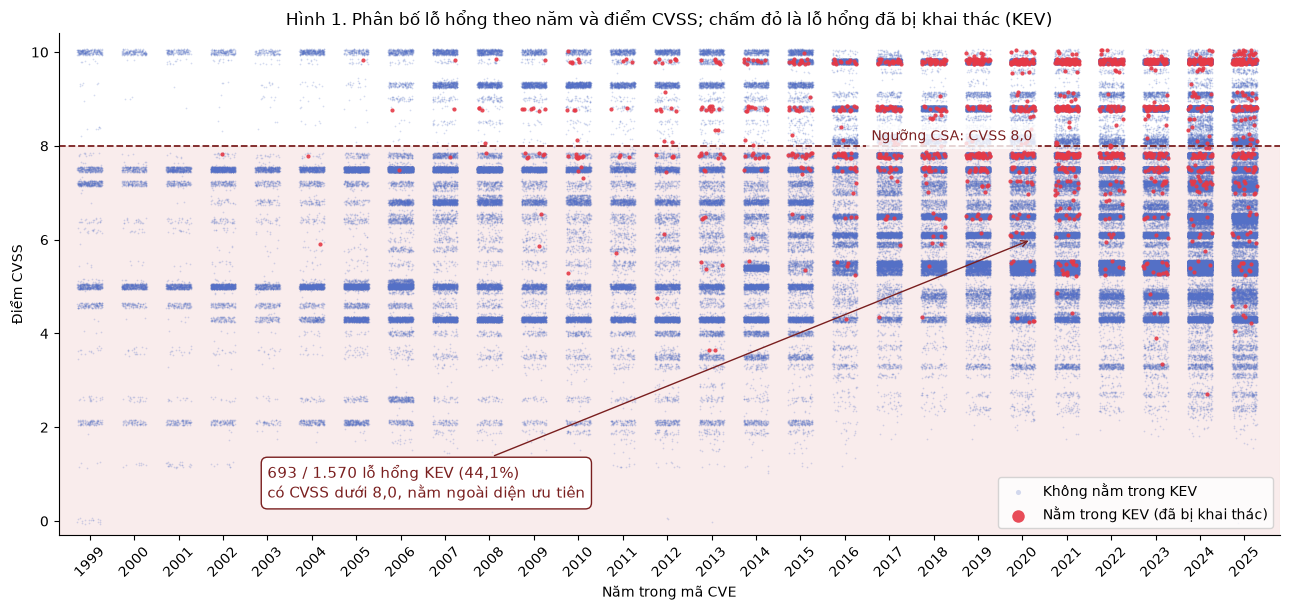

In [11]:
rng = np.random.default_rng(42)
d = df[df["cvss"].notna()].copy()
d["x"] = d["nam"] + rng.uniform(-0.28, 0.28, len(d)); d["y"] = d["cvss"] + rng.uniform(-0.06, 0.06, len(d))
xanh, do = d[~d["kev"]], d[d["kev"]]
r = SO_LIEU["1999 đến 2025"]
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.axhspan(-0.3, NGUONG, color="#f2d7d5", alpha=0.45, zorder=0)
ax.scatter(xanh["x"], xanh["y"], s=1.5, c="#5470c6", alpha=0.25, lw=0, rasterized=True, label="Không nằm trong KEV", zorder=1)
ax.scatter(do["x"], do["y"], s=9, c="#e63946", alpha=0.9, lw=0, label="Nằm trong KEV (đã bị khai thác)", zorder=3)
ax.axhline(NGUONG, color="#7a1f1f", lw=1.3, ls="--", zorder=2)
ax.text(2016.6, NGUONG + 0.12, "Ngưỡng CSA: CVSS 8,0", fontsize=10, color="#7a1f1f",
        bbox=dict(fc="white", ec="none", alpha=0.8))
ax.annotate(f"{so(r['c'])} / {so(r['K'])} lỗ hổng KEV ({pct(100*r['c']/r['K'], 1)}%)\ncó CVSS dưới 8,0, nằm ngoài diện ưu tiên",
            xy=(2020.2, 6.0), xytext=(2003, 0.5), fontsize=11, color="#7a1f1f",
            arrowprops=dict(arrowstyle="->", color="#7a1f1f"), bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#7a1f1f"))
ax.set_xlim(1998.3, END_YEAR + 0.8); ax.set_ylim(-0.3, 10.4)
ax.set_xticks(range(1999, END_YEAR + 1)); ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Năm trong mã CVE"); ax.set_ylabel("Điểm CVSS")
ax.set_title("Hình 1. Phân bố lỗ hổng theo năm và điểm CVSS; chấm đỏ là lỗ hổng đã bị khai thác (KEV)")
ax.legend(loc="lower right", markerscale=3)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh1_phan_bo.png"), dpi=170); plt.show()

## 12. Hình 2. Ngưỡng 8,0 xử lý hai nhóm lỗ hổng ra sao

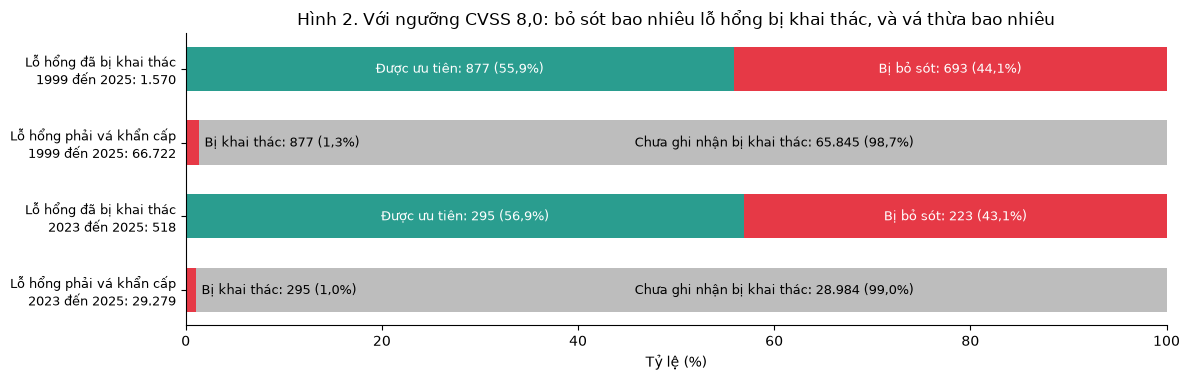

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.9))
cac_dong = []
for ten in GIAI_DOAN:
    r = SO_LIEU[ten]
    cac_dong.append((f"Lỗ hổng đã bị khai thác\n{ten}: {so(r['K'])}", r["a"], r["c"], r["K"],
                 "Được ưu tiên", "Bị bỏ sót", "#2a9d8f", "#e63946"))
    cac_dong.append((f"Lỗ hổng phải vá khẩn cấp\n{ten}: {so(r['cao'])}", r["a"], r["b"], r["cao"],
                 "Bị khai thác", "Chưa ghi nhận bị khai thác", "#e63946", "#bdbdbd"))
for i, (nhan, v1, v2, tong, n1, n2, m1, m2) in enumerate(cac_dong):
    y = len(cac_dong) - 1 - i; p1, p2 = 100 * v1 / tong, 100 * v2 / tong
    ax.barh(y, p1, color=m1, height=0.6); ax.barh(y, p2, left=p1, color=m2, height=0.6)
    ax.text(p1 / 2 if p1 > 8 else p1 + 0.6, y, f"{n1}: {so(v1)} ({pct(p1, 1)}%)", va="center",
            ha="center" if p1 > 8 else "left", fontsize=9, color="white" if p1 > 8 else "black")
    ax.text(p1 + p2 / 2 if p1 > 8 else 60, y, f"{n2}: {so(v2)} ({pct(p2, 1)}%)", va="center", ha="center", fontsize=9,
            color="white" if m2 != "#bdbdbd" else "black")
ax.set_yticks(range(len(cac_dong))); ax.set_yticklabels([d[0] for d in cac_dong][::-1], fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("Tỷ lệ (%)")
ax.set_title("Hình 2. Với ngưỡng CVSS 8,0: bỏ sót bao nhiêu lỗ hổng bị khai thác, và vá thừa bao nhiêu")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh2_hai_loi.png"), dpi=170); plt.show()

## 13. Hình 3. Tỷ lệ lỗ hổng KEV có CVSS dưới 8,0 theo năm

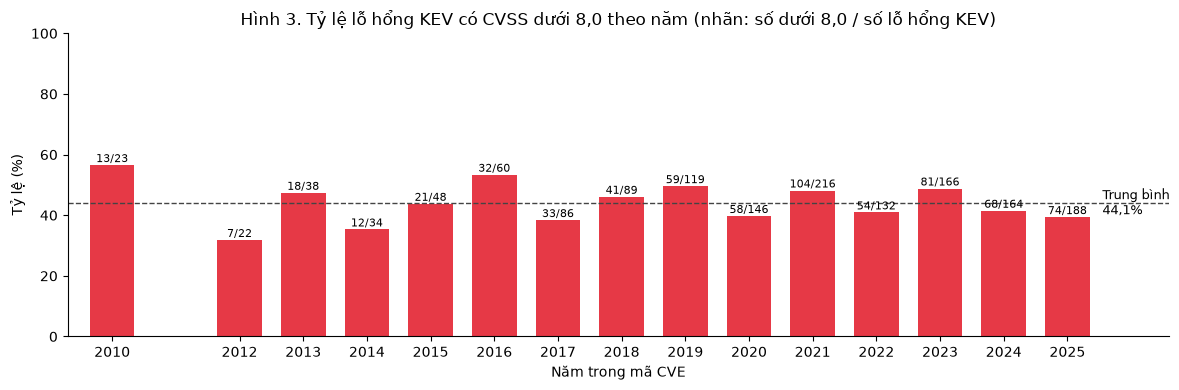

In [13]:
t = t7[t7["kev"] >= 10]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(t.index, 100 * t["duoi"] / t["kev"], color="#e63946", width=0.7)
for x, dd, kk in zip(t.index, t["duoi"], t["kev"]):
    ax.text(x, 100 * dd / kk + 1, f"{dd}/{kk}", ha="center", fontsize=8)
tb = 100 * SO_LIEU["1999 đến 2025"]["c"] / SO_LIEU["1999 đến 2025"]["K"]
ax.axhline(tb, color="#444", ls="--", lw=1)
ax.text(t.index.max() + 0.55, tb, f"Trung bình\n{pct(tb, 1)}%", fontsize=9, va="center")
ax.set_xlim(t.index.min() - 0.7, t.index.max() + 1.6)
ax.set_xticks(t.index); ax.set_ylim(0, 100); ax.set_ylabel("Tỷ lệ (%)"); ax.set_xlabel("Năm trong mã CVE")
ax.set_title("Hình 3. Tỷ lệ lỗ hổng KEV có CVSS dưới 8,0 theo năm (nhãn: số dưới 8,0 / số lỗ hổng KEV)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh3_theo_nam.png"), dpi=170); plt.show()

## 14. Hình 4. Phân bố điểm CVSS: tất cả lỗ hổng so với lỗ hổng bị khai thác

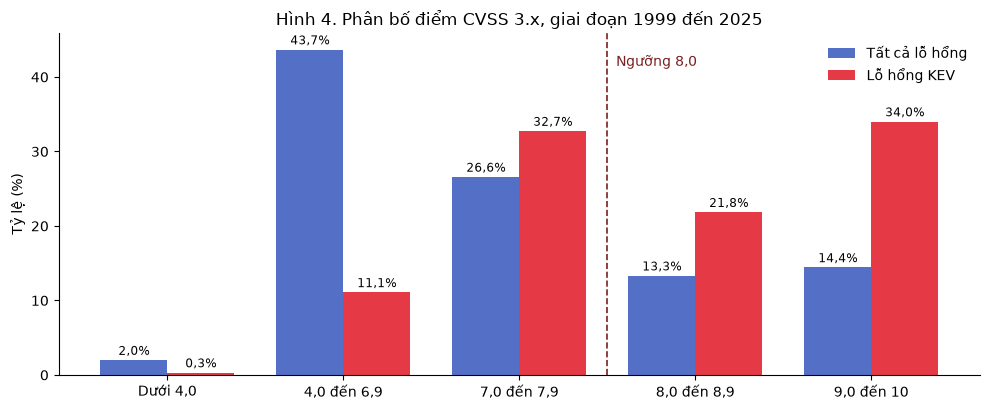

In [14]:
tt = co3.groupby("khoang", observed=False).agg(tat_ca=("cve", "size"), kev=("kev", "sum"))
p_all, p_kev = 100 * tt["tat_ca"] / tt["tat_ca"].sum(), 100 * tt["kev"] / tt["kev"].sum()
x = np.arange(len(NHAN)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.2))
b1_ = ax.bar(x - w / 2, p_all, w, color="#5470c6", label="Tất cả lỗ hổng")
b2_ = ax.bar(x + w / 2, p_kev, w, color="#e63946", label="Lỗ hổng KEV")
for bars in (b1_, b2_):
    for bb in bars:
        ax.text(bb.get_x() + bb.get_width() / 2, bb.get_height() + 0.7, f"{pct(bb.get_height(), 1)}%", ha="center", fontsize=8.5)
ax.axvline(2.5, color="#7a1f1f", ls="--", lw=1.2); ax.text(2.55, max(p_kev.max(), p_all.max()) * 0.95, "Ngưỡng 8,0", color="#7a1f1f")
ax.set_xticks(x); ax.set_xticklabels(NHAN); ax.set_ylabel("Tỷ lệ (%)"); ax.legend(frameon=False)
ax.set_title("Hình 4. Phân bố điểm CVSS 3.x, giai đoạn 1999 đến 2025")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh4_phan_bo_cvss.png"), dpi=170); plt.show()

## 15. Vấn đề 1. Nhóm CVSS từ 8,0 phải vá trong 48 giờ, nhưng gần như toàn bộ chưa từng bị khai thác

Theo khuyến nghị của CSA, mọi lỗ hổng CVSS từ 8,0 phải được vá trong 48 giờ. Phần này đo xem trong nhóm đó có bao nhiêu lỗ hổng thực sự đã bị khai thác (nằm trong KEV) và bao nhiêu chưa từng được ghi nhận bị khai thác. "Chưa ghi nhận" không có nghĩa là an toàn tuyệt đối, chỉ là chưa có bằng chứng khai thác công khai.

In [15]:
b10 = []
for ten, (y0, y1) in GIAI_DOAN.items():
    x = co3[co3["nam"].between(y0, y1)]
    for nh, lo, hi in [("8,0 đến 8,9", 8.0, 9.0), ("9,0 đến 10", 9.0, 10.01), ("Cả nhóm từ 8,0", 8.0, 10.01)]:
        g = x[(x["cvss"] >= lo) & (x["cvss"] < hi)]; n, k = len(g), int(g["kev"].sum())
        b10.append([ten, nh, so(n), ty_le(k, n), ty_le(n - k, n), pct(n / k, 1)])
b10 = pd.DataFrame(b10, columns=["Giai đoạn", "Khoảng CVSS", "Phải vá trong 48 giờ", "Đã bị khai thác (KEV)",
                                 "Chưa ghi nhận bị khai thác", "Số lỗ hổng phải vá cho 1 lỗ hổng KEV"])
BANG["B10 Van de 1 va thua"] = b10
display(b10)

# Khoi luong cong viec theo tung nam
b11, SO_LIEU["khoi_luong"] = [], {}
for y in range(2020, END_YEAR + 1):
    g = co3[(co3["nam"] == y) & (co3["cvss"] >= NGUONG)]; n, k = len(g), int(g["kev"].sum())
    SO_LIEU["khoi_luong"][y] = dict(n=n, k=k)
    b11.append([y, so(n), pct(n / 365, 1), ty_le(k, n), ty_le(n - k, n)])
b11 = pd.DataFrame(b11, columns=["Năm", "Lỗ hổng CVSS từ 8,0", "Trung bình mỗi ngày", "Đã bị khai thác (KEV)",
                                 "Chưa ghi nhận bị khai thác"])
BANG["B11 Khoi luong theo nam"] = b11
display(b11)

,Giai đoạn,Khoảng CVSS,Phải vá trong 48 giờ,Đã bị khai thác (KEV),Chưa ghi nhận bị khai thác,Số lỗ hổng phải vá cho 1 lỗ hổng KEV
0,1999 đến 2025,"8,0 đến 8,9",32.025,"343 / 32.025 = 1,07%","31.682 / 32.025 = 98,93%","93,4"
1,1999 đến 2025,"9,0 đến 10",34.697,"534 / 34.697 = 1,54%","34.163 / 34.697 = 98,46%","65,0"
2,1999 đến 2025,"Cả nhóm từ 8,0",66.722,"877 / 66.722 = 1,31%","65.845 / 66.722 = 98,69%","76,1"
3,2023 đến 2025,"8,0 đến 8,9",14.116,"100 / 14.116 = 0,71%","14.016 / 14.116 = 99,29%","141,2"
4,2023 đến 2025,"9,0 đến 10",15.163,"195 / 15.163 = 1,29%","14.968 / 15.163 = 98,71%","77,8"
5,2023 đến 2025,"Cả nhóm từ 8,0",29.279,"295 / 29.279 = 1,01%","28.984 / 29.279 = 98,99%","99,3"


,Năm,"Lỗ hổng CVSS từ 8,0",Trung bình mỗi ngày,Đã bị khai thác (KEV),Chưa ghi nhận bị khai thác
0,2020,5.532,"15,2","88 / 5.532 = 1,59%","5.444 / 5.532 = 98,41%"
1,2021,5.603,"15,4","112 / 5.603 = 2,00%","5.491 / 5.603 = 98,00%"
2,2022,6.879,"18,8","78 / 6.879 = 1,13%","6.801 / 6.879 = 98,87%"
3,2023,8.416,"23,1","85 / 8.416 = 1,01%","8.331 / 8.416 = 98,99%"
4,2024,9.693,"26,6","96 / 9.693 = 0,99%","9.597 / 9.693 = 99,01%"
5,2025,11.170,"30,6","114 / 11.170 = 1,02%","11.056 / 11.170 = 98,98%"


## 16. Hình 5. Số lỗ hổng CVSS từ 8,0 mỗi năm và phần thực sự bị khai thác

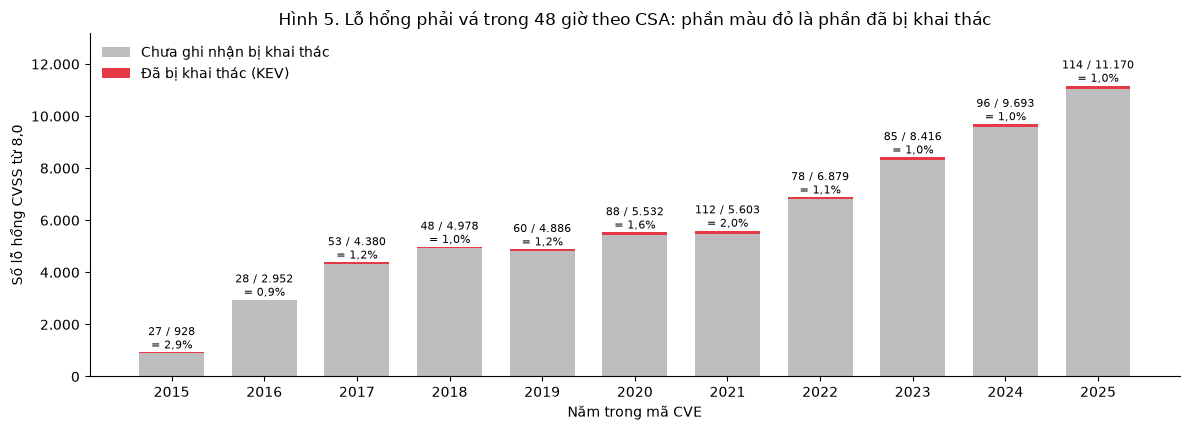

In [16]:
kl = co3[(co3["cvss"] >= NGUONG) & (co3["nam"] >= 2015)].groupby("nam")["kev"].agg(["size", "sum"])
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.bar(kl.index, kl["size"] - kl["sum"], color="#bdbdbd", width=0.7, label="Chưa ghi nhận bị khai thác")
ax.bar(kl.index, kl["sum"], bottom=kl["size"] - kl["sum"], color="#e63946", width=0.7, label="Đã bị khai thác (KEV)")
for x, n, k in zip(kl.index, kl["size"], kl["sum"]):
    ax.text(x, n + 150, f"{so(k)} / {so(n)}\n= {pct(100 * k / n, 1)}%", ha="center", fontsize=8)
ax.set_ylim(0, kl["size"].max() * 1.18); ax.set_xticks(kl.index)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: so(v)))
ax.set_ylabel("Số lỗ hổng CVSS từ 8,0"); ax.set_xlabel("Năm trong mã CVE"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Hình 5. Lỗ hổng phải vá trong 48 giờ theo CSA: phần màu đỏ là phần đã bị khai thác")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh5_van_de_1.png"), dpi=170); plt.show()

## 17. Vấn đề 2. Lỗ hổng đã bị khai thác nhưng CVSS dưới 8,0 nên bị bỏ qua

Các lỗ hổng này đã được CISA xác nhận bị khai thác trong thực tế, nhưng theo quy tắc của CSA chúng không thuộc diện vá trong 48 giờ. Phần này chia nhỏ nhóm bị bỏ qua theo khoảng điểm và so sánh mức độ được dùng trong các chiến dịch mã độc tống tiền (trường knownRansomwareCampaignUse của KEV).

In [17]:
kv = co3[co3["kev"]].merge(kev[["cveID", "knownRansomwareCampaignUse"]], left_on="cve", right_on="cveID")
kv["rw"] = kv["knownRansomwareCampaignUse"].eq("Known")
b12 = []
for ten, (y0, y1) in GIAI_DOAN.items():
    x = kv[kv["nam"].between(y0, y1)]; K = len(x); bs = x[x["cvss"] < NGUONG]; c = len(bs)
    for nh, lo, hi in [("Dưới 4,0", 0, 4), ("4,0 đến 6,9", 4, 7), ("7,0 đến 7,9", 7, 8), ("Cả nhóm dưới 8,0", 0, 8)]:
        n = int(((bs["cvss"] >= lo) & (bs["cvss"] < hi)).sum())
        b12.append([ten, nh, so(n), ty_le(n, c), ty_le(n, K)])
b12 = pd.DataFrame(b12, columns=["Giai đoạn", "Khoảng CVSS", "Số lỗ hổng KEV bị bỏ qua",
                                 "So với nhóm bị bỏ qua", "So với toàn bộ nhóm KEV"])
BANG["B12 Van de 2 bo sot"] = b12
display(b12)

x = kv; cao, thap = x[x["cvss"] >= NGUONG], x[x["cvss"] < NGUONG]
rw = int(x["rw"].sum()); rw_c, rw_t = int(thap["rw"].sum()), int(cao["rw"].sum())
b13 = pd.DataFrame([
    ["CVSS từ 8,0 (được vá trong 48 giờ)", so(len(cao)), ty_le(rw_t, len(cao)), ty_le(rw_t, rw)],
    ["CVSS dưới 8,0 (bị bỏ qua)", so(len(thap)), ty_le(rw_c, len(thap)), ty_le(rw_c, rw)],
    ["Toàn bộ nhóm KEV", so(len(x)), ty_le(rw, len(x)), ty_le(rw, rw)],
], columns=["Nhóm lỗ hổng KEV (1999 đến 2025)", "Số lượng", "Đã dùng trong mã độc tống tiền",
            "So với tổng số lỗ hổng KEV dùng trong mã độc tống tiền"])
BANG["B13 Ma doc tong tien"] = b13
SO_LIEU["ransomware"] = dict(tong=rw, cao=rw_t, thap=rw_c, n_cao=len(cao), n_thap=len(thap))
display(b13)

,Giai đoạn,Khoảng CVSS,Số lỗ hổng KEV bị bỏ qua,So với nhóm bị bỏ qua,So với toàn bộ nhóm KEV
0,1999 đến 2025,"Dưới 4,0",5,"5 / 693 = 0,72%","5 / 1.570 = 0,32%"
1,1999 đến 2025,"4,0 đến 6,9",174,"174 / 693 = 25,11%","174 / 1.570 = 11,08%"
2,1999 đến 2025,"7,0 đến 7,9",514,"514 / 693 = 74,17%","514 / 1.570 = 32,74%"
3,1999 đến 2025,"Cả nhóm dưới 8,0",693,"693 / 693 = 100,00%","693 / 1.570 = 44,14%"
4,2023 đến 2025,"Dưới 4,0",3,"3 / 223 = 1,35%","3 / 518 = 0,58%"
5,2023 đến 2025,"4,0 đến 6,9",64,"64 / 223 = 28,70%","64 / 518 = 12,36%"
6,2023 đến 2025,"7,0 đến 7,9",156,"156 / 223 = 69,96%","156 / 518 = 30,12%"
7,2023 đến 2025,"Cả nhóm dưới 8,0",223,"223 / 223 = 100,00%","223 / 518 = 43,05%"


,Nhóm lỗ hổng KEV (1999 đến 2025),Số lượng,Đã dùng trong mã độc tống tiền,So với tổng số lỗ hổng KEV dùng trong mã độc tống tiền
0,"CVSS từ 8,0 (được vá trong 48 giờ)",877,"198 / 877 = 22,58%","198 / 343 = 57,73%"
1,"CVSS dưới 8,0 (bị bỏ qua)",693,"145 / 693 = 20,92%","145 / 343 = 42,27%"
2,Toàn bộ nhóm KEV,1.570,"343 / 1.570 = 21,85%","343 / 343 = 100,00%"


## 18. Hình 6. 1.570 lỗ hổng đã bị khai thác nằm ở đâu so với ngưỡng 8,0

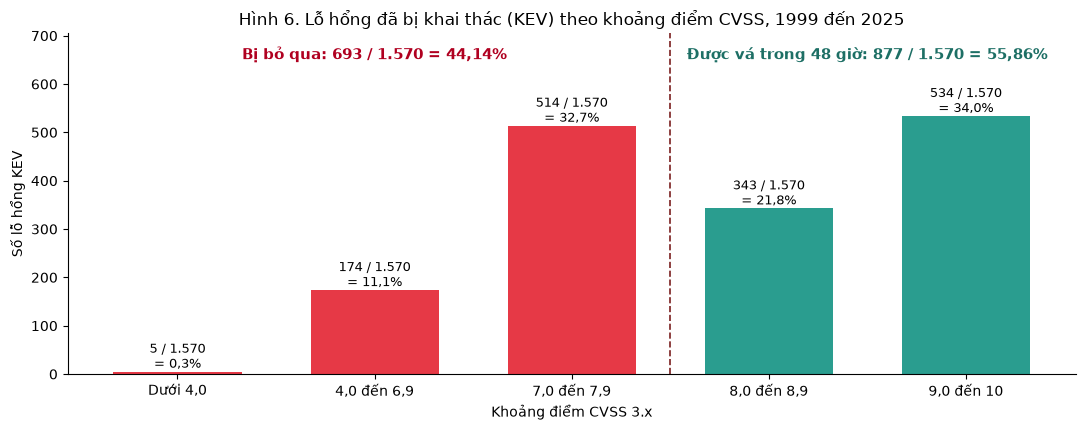

In [18]:
tt = co3[co3["kev"]].groupby("khoang", observed=False).size()
K = int(tt.sum()); mau = ["#e63946"] * 3 + ["#2a9d8f"] * 2
fig, ax = plt.subplots(figsize=(11, 4.4))
bars = ax.bar(NHAN, tt.values, color=mau, width=0.65)
for bb, v in zip(bars, tt.values):
    ax.text(bb.get_x() + bb.get_width() / 2, v + 8, f"{so(v)} / {so(K)}\n= {pct(100 * v / K, 1)}%", ha="center", fontsize=9)
ax.axvline(2.5, color="#7a1f1f", ls="--", lw=1.2)
c = int(tt.values[:3].sum()); a = K - c
ax.text(1.0, tt.max() * 1.22, f"Bị bỏ qua: {so(c)} / {so(K)} = {pct(100 * c / K)}%", ha="center", color="#b00020", fontsize=11, weight="bold")
ax.text(3.5, tt.max() * 1.22, f"Được vá trong 48 giờ: {so(a)} / {so(K)} = {pct(100 * a / K)}%", ha="center", color="#1d6f65", fontsize=11, weight="bold")
ax.set_ylim(0, tt.max() * 1.32); ax.set_ylabel("Số lỗ hổng KEV"); ax.set_xlabel("Khoảng điểm CVSS 3.x")
ax.set_title("Hình 6. Lỗ hổng đã bị khai thác (KEV) theo khoảng điểm CVSS, 1999 đến 2025")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh6_van_de_2.png"), dpi=170); plt.show()

## 19. Bảng 14, 15, 16. Phân bổ theo bậc điểm EPSS

Chia lỗ hổng theo bậc điểm EPSS, trong mỗi bậc đếm bốn nhóm: CVSS từ 8,0 có trong KEV, CVSS từ 8,0 không có trong KEV, CVSS dưới 8,0 có trong KEV, CVSS dưới 8,0 không có trong KEV.

- Bảng 14: tỷ lệ so với tổng số lỗ hổng của **bậc đó** (đọc theo hàng).
- Bảng 15: tỷ lệ so với tổng số lỗ hổng của **nhóm đó** (đọc theo cột), cho biết mỗi nhóm phân bố ra sao trên các bậc EPSS.
- Bảng 16: trong từng bậc, tỷ lệ nằm trong KEV của phía CVSS từ 8,0 và phía dưới 8,0.

**Lưu ý:** dùng điểm EPSS tại một ngày cố định (EPSS_NGAY), sau khi phần lớn lỗ hổng KEV đã được ghi nhận bị khai thác. Bằng chứng khai thác là một đầu vào của EPSS, nên điểm của nhóm KEV cao một phần do đã biết kết quả. Bảng này mô tả hiện trạng, không chứng minh EPSS dự báo được trước.

In [19]:
EPSS_NGAY = "2026-10-13"
EPSS_URL = f"https://epss.empiricalsecurity.com/epss_scores-{EPSS_NGAY}.csv.gz"
raw = gzip.decompress(tai(EPSS_URL, os.path.join(DATA_DIR, f"epss_{EPSS_NGAY}.csv.gz"))).decode()
print("Tệp EPSS:", raw.splitlines()[0])
ep = pd.read_csv(io.StringIO(raw), comment="#")
co3["epss"] = co3["cve"].map(dict(zip(ep["cve"].str.upper(), ep["epss"]))).fillna(0.0)
print(f"Lỗ hổng không có điểm EPSS (coi là 0): {so((~co3['cve'].isin(set(ep['cve'].str.upper()))).sum())}")

BAC = [0, 0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0001]
NHAN_E = ["Dưới 0,001", "0,001 đến dưới 0,01", "0,01 đến dưới 0,05", "0,05 đến dưới 0,1", "0,1 đến dưới 0,3",
          "0,3 đến dưới 0,5", "0,5 đến dưới 0,7", "0,7 đến dưới 0,9", "0,9 đến 1"]
co3["bac_epss"] = pd.cut(co3["epss"], BAC, labels=NHAN_E, right=False)
cao = co3["cvss"] >= NGUONG
co3["nhom"] = np.select([cao & co3["kev"], cao & ~co3["kev"], ~cao & co3["kev"]],
                        ["CVSS từ 8,0, có KEV", "CVSS từ 8,0, không KEV", "CVSS dưới 8,0, có KEV"], "CVSS dưới 8,0, không KEV")
NHOM = ["CVSS từ 8,0, có KEV", "CVSS từ 8,0, không KEV", "CVSS dưới 8,0, có KEV", "CVSS dưới 8,0, không KEV"]
bt = pd.crosstab(co3["bac_epss"], co3["nhom"]).reindex(index=NHAN_E, columns=NHOM, fill_value=0)
tong_bac, tong_nhom, N = bt.sum(axis=1), bt.sum(axis=0), int(bt.values.sum())

def tl(a, b):
    """Ty le co tu so va mau so; so rat nho thi lay 3 chu so thap phan"""
    if b == 0: return ""
    return ty_le(a, b, 3 if 0 < 100 * a / b < 0.1 else 2)

b14 = pd.DataFrame({"Bậc EPSS": NHAN_E + ["Tổng"],
                    "Tổng số lỗ hổng trong bậc": [ty_le(v, N) for v in tong_bac] + [so(N)]})
for g in NHOM:
    b14[g] = [tl(bt.loc[b, g], tong_bac[b]) for b in NHAN_E] + [ty_le(tong_nhom[g], N)]
b15 = pd.DataFrame({"Bậc EPSS": NHAN_E + ["Tổng"]})
for g in NHOM:
    b15[g] = [tl(bt.loc[b, g], tong_nhom[g]) for b in NHAN_E] + [so(tong_nhom[g])]
b16 = pd.DataFrame({
    "Bậc EPSS": NHAN_E,
    "Phía CVSS từ 8,0: tỷ lệ có KEV": [tl(bt.loc[b, NHOM[0]], bt.loc[b, NHOM[0]] + bt.loc[b, NHOM[1]]) for b in NHAN_E],
    "Phía CVSS dưới 8,0: tỷ lệ có KEV": [tl(bt.loc[b, NHOM[2]], bt.loc[b, NHOM[2]] + bt.loc[b, NHOM[3]]) for b in NHAN_E],
    "Cả bậc: tỷ lệ có KEV": [tl(bt.loc[b, NHOM[0]] + bt.loc[b, NHOM[2]], tong_bac[b]) for b in NHAN_E]})
BANG["B14 EPSS theo bac"] = b14; BANG["B15 EPSS theo nhom"] = b15; BANG["B16 EPSS ty le KEV"] = b16
SO_LIEU["epss_ngay"] = EPSS_NGAY; SO_LIEU["epss_mo_hinh"] = raw.splitlines()[0]
SO_LIEU["epss_bac"] = {b: {g: int(bt.loc[b, g]) for g in NHOM} for b in NHAN_E}
print("\nBảng 14. So với tổng số lỗ hổng trong bậc"); display(b14)
print("\nBảng 15. So với tổng số lỗ hổng của nhóm"); display(b15)
print("\nBảng 16. Tỷ lệ nằm trong KEV trong từng bậc"); display(b16)

Tệp EPSS: #model_version:v2026.06.15,score_date:2026-10-13T12:03:00Z


Lỗ hổng không có điểm EPSS (coi là 0): 0

Bảng 14. So với tổng số lỗ hổng trong bậc


,Bậc EPSS,Tổng số lỗ hổng trong bậc,"CVSS từ 8,0, có KEV","CVSS từ 8,0, không KEV","CVSS dưới 8,0, có KEV","CVSS dưới 8,0, không KEV"
0,"Dưới 0,001","2.260 / 240.409 = 0,94%","0 / 2.260 = 0,00%","38 / 2.260 = 1,68%","0 / 2.260 = 0,00%","2.222 / 2.260 = 98,32%"
1,"0,001 đến dưới 0,01","153.067 / 240.409 = 63,67%","3 / 153.067 = 0,002%","29.311 / 153.067 = 19,15%","33 / 153.067 = 0,022%","123.720 / 153.067 = 80,83%"
2,"0,01 đến dưới 0,05","68.877 / 240.409 = 28,65%","60 / 68.877 = 0,087%","28.469 / 68.877 = 41,33%","158 / 68.877 = 0,23%","40.190 / 68.877 = 58,35%"
3,"0,05 đến dưới 0,1","6.300 / 240.409 = 2,62%","51 / 6.300 = 0,81%","3.288 / 6.300 = 52,19%","58 / 6.300 = 0,92%","2.903 / 6.300 = 46,08%"
4,"0,1 đến dưới 0,3","5.352 / 240.409 = 2,23%","127 / 5.352 = 2,37%","2.642 / 5.352 = 49,36%","117 / 5.352 = 2,19%","2.466 / 5.352 = 46,08%"
5,"0,3 đến dưới 0,5","1.509 / 240.409 = 0,63%","72 / 1.509 = 4,77%","811 / 1.509 = 53,74%","59 / 1.509 = 3,91%","567 / 1.509 = 37,57%"
6,"0,5 đến dưới 0,7","1.166 / 240.409 = 0,49%","64 / 1.166 = 5,49%","539 / 1.166 = 46,23%","70 / 1.166 = 6,00%","493 / 1.166 = 42,28%"
7,"0,7 đến dưới 0,9","1.185 / 240.409 = 0,49%","142 / 1.185 = 11,98%","594 / 1.185 = 50,13%","103 / 1.185 = 8,69%","346 / 1.185 = 29,20%"
8,"0,9 đến 1","693 / 240.409 = 0,29%","358 / 693 = 51,66%","153 / 693 = 22,08%","95 / 693 = 13,71%","87 / 693 = 12,55%"
9,Tổng,240.409,"877 / 240.409 = 0,36%","65.845 / 240.409 = 27,39%","693 / 240.409 = 0,29%","172.994 / 240.409 = 71,96%"



Bảng 15. So với tổng số lỗ hổng của nhóm


,Bậc EPSS,"CVSS từ 8,0, có KEV","CVSS từ 8,0, không KEV","CVSS dưới 8,0, có KEV","CVSS dưới 8,0, không KEV"
0,"Dưới 0,001","0 / 877 = 0,00%","38 / 65.845 = 0,058%","0 / 693 = 0,00%","2.222 / 172.994 = 1,28%"
1,"0,001 đến dưới 0,01","3 / 877 = 0,34%","29.311 / 65.845 = 44,52%","33 / 693 = 4,76%","123.720 / 172.994 = 71,52%"
2,"0,01 đến dưới 0,05","60 / 877 = 6,84%","28.469 / 65.845 = 43,24%","158 / 693 = 22,80%","40.190 / 172.994 = 23,23%"
3,"0,05 đến dưới 0,1","51 / 877 = 5,82%","3.288 / 65.845 = 4,99%","58 / 693 = 8,37%","2.903 / 172.994 = 1,68%"
4,"0,1 đến dưới 0,3","127 / 877 = 14,48%","2.642 / 65.845 = 4,01%","117 / 693 = 16,88%","2.466 / 172.994 = 1,43%"
5,"0,3 đến dưới 0,5","72 / 877 = 8,21%","811 / 65.845 = 1,23%","59 / 693 = 8,51%","567 / 172.994 = 0,33%"
6,"0,5 đến dưới 0,7","64 / 877 = 7,30%","539 / 65.845 = 0,82%","70 / 693 = 10,10%","493 / 172.994 = 0,28%"
7,"0,7 đến dưới 0,9","142 / 877 = 16,19%","594 / 65.845 = 0,90%","103 / 693 = 14,86%","346 / 172.994 = 0,20%"
8,"0,9 đến 1","358 / 877 = 40,82%","153 / 65.845 = 0,23%","95 / 693 = 13,71%","87 / 172.994 = 0,050%"
9,Tổng,877,65.845,693,172.994



Bảng 16. Tỷ lệ nằm trong KEV trong từng bậc


,Bậc EPSS,"Phía CVSS từ 8,0: tỷ lệ có KEV","Phía CVSS dưới 8,0: tỷ lệ có KEV",Cả bậc: tỷ lệ có KEV
0,"Dưới 0,001","0 / 38 = 0,00%","0 / 2.222 = 0,00%","0 / 2.260 = 0,00%"
1,"0,001 đến dưới 0,01","3 / 29.314 = 0,010%","33 / 123.753 = 0,027%","36 / 153.067 = 0,024%"
2,"0,01 đến dưới 0,05","60 / 28.529 = 0,21%","158 / 40.348 = 0,39%","218 / 68.877 = 0,32%"
3,"0,05 đến dưới 0,1","51 / 3.339 = 1,53%","58 / 2.961 = 1,96%","109 / 6.300 = 1,73%"
4,"0,1 đến dưới 0,3","127 / 2.769 = 4,59%","117 / 2.583 = 4,53%","244 / 5.352 = 4,56%"
5,"0,3 đến dưới 0,5","72 / 883 = 8,15%","59 / 626 = 9,42%","131 / 1.509 = 8,68%"
6,"0,5 đến dưới 0,7","64 / 603 = 10,61%","70 / 563 = 12,43%","134 / 1.166 = 11,49%"
7,"0,7 đến dưới 0,9","142 / 736 = 19,29%","103 / 449 = 22,94%","245 / 1.185 = 20,68%"
8,"0,9 đến 1","358 / 511 = 70,06%","95 / 182 = 52,20%","453 / 693 = 65,37%"


## 20. Hình 7. Bốn nhóm phân bố trên các bậc EPSS

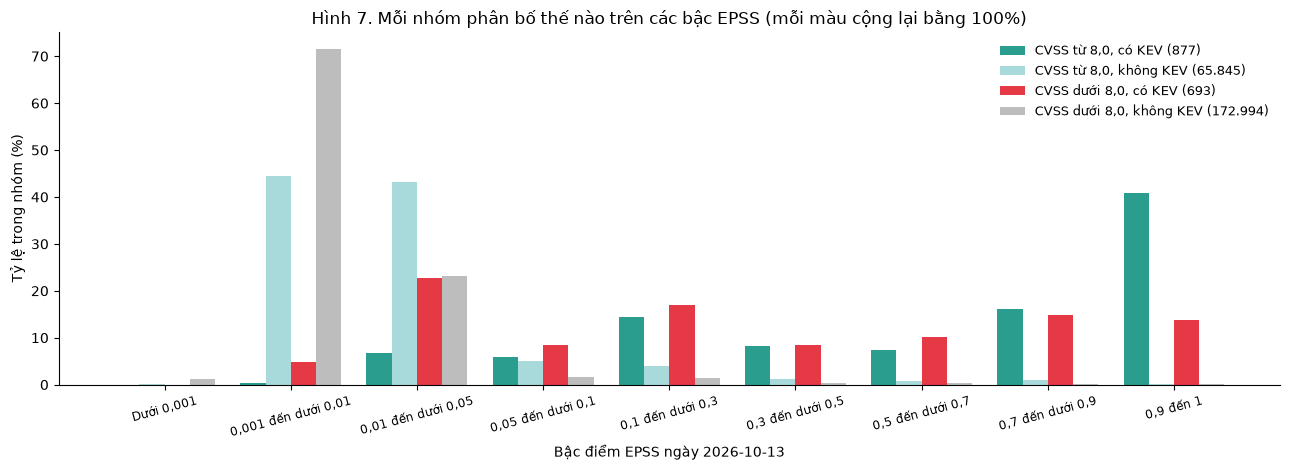

In [20]:
fig, ax = plt.subplots(figsize=(13, 4.8))
x = np.arange(len(NHAN_E)); w = 0.2
mau = {"CVSS từ 8,0, có KEV": "#2a9d8f", "CVSS từ 8,0, không KEV": "#a8dadc",
       "CVSS dưới 8,0, có KEV": "#e63946", "CVSS dưới 8,0, không KEV": "#bdbdbd"}
for i, g in enumerate(NHOM):
    p = 100 * bt[g] / tong_nhom[g]
    ax.bar(x + (i - 1.5) * w, p, w, color=mau[g], label=f"{g} ({so(tong_nhom[g])})")
ax.set_xticks(x); ax.set_xticklabels(NHAN_E, fontsize=8.5, rotation=15)
ax.set_ylabel("Tỷ lệ trong nhóm (%)"); ax.set_xlabel(f"Bậc điểm EPSS ngày {EPSS_NGAY}")
ax.legend(frameon=False, fontsize=9)
ax.set_title("Hình 7. Mỗi nhóm phân bố thế nào trên các bậc EPSS (mỗi màu cộng lại bằng 100%)")
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "hinh7_epss.png"), dpi=170); plt.show()

## 21. Nhận xét tự động từ số liệu

In [21]:
A, B = SO_LIEU["1999 đến 2025"], SO_LIEU["2023 đến 2025"]
print(f"""1. Ngưỡng 8,0 bỏ sót {so(A['c'])} / {so(A['K'])} = {pct(100*A['c']/A['K'])}% lỗ hổng đã bị khai thác.
2. Trong {so(A['cao'])} lỗ hổng phải vá khẩn cấp, {so(A['b'])} / {so(A['cao'])} = {pct(100*A['b']/A['cao'])}% chưa ghi nhận bị khai thác;
   trung bình phải vá {pct(A['cao']/A['a'], 1)} lỗ hổng mới bắt được 1 lỗ hổng bị khai thác.
3. Nhóm từ 8,0 bị khai thác {pct(100*A['a']/A['cao'])}%, nhóm dưới 8,0 là {pct(100*A['c']/A['thap'])}%,
   gấp {pct((A['a']/A['cao'])/(A['c']/A['thap']))} lần.
4. Giai đoạn 2023 đến 2025: bỏ sót {so(B['c'])} / {so(B['K'])} = {pct(100*B['c']/B['K'])}%,
   phải vá {pct(B['cao']/B['a'], 1)} lỗ hổng cho mỗi lỗ hổng bị khai thác bắt được.""")

1. Ngưỡng 8,0 bỏ sót 693 / 1.570 = 44,14% lỗ hổng đã bị khai thác.
2. Trong 66.722 lỗ hổng phải vá khẩn cấp, 65.845 / 66.722 = 98,69% chưa ghi nhận bị khai thác;
   trung bình phải vá 76,1 lỗ hổng mới bắt được 1 lỗ hổng bị khai thác.
3. Nhóm từ 8,0 bị khai thác 1,31%, nhóm dưới 8,0 là 0,40%,
   gấp 3,29 lần.
4. Giai đoạn 2023 đến 2025: bỏ sót 223 / 518 = 43,05%,
   phải vá 99,3 lỗ hổng cho mỗi lỗ hổng bị khai thác bắt được.


## 22. Lưu kết quả

In [22]:
with pd.ExcelWriter(os.path.join(OUT_DIR, "bang_thong_ke.xlsx")) as w:
    for ten, b in BANG.items():
        b.to_excel(w, sheet_name=ten[:31], index=False)
for ten, b in BANG.items():
    b.to_csv(os.path.join(OUT_DIR, ten.replace(" ", "_") + ".csv"), index=False, encoding="utf-8-sig")
json.dump(SO_LIEU, open(os.path.join(OUT_DIR, "so_lieu.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2,
          default=lambda o: int(o) if isinstance(o, (np.integer,)) else float(o))
print("Đã lưu vào thư mục", OUT_DIR, ":", ", ".join(sorted(os.listdir(OUT_DIR))))

Đã lưu vào thư mục ket_qua : B10_Van_de_1_va_thua.csv, B11_Khoi_luong_theo_nam.csv, B12_Van_de_2_bo_sot.csv, B13_Ma_doc_tong_tien.csv, B14_EPSS_theo_bac.csv, B15_EPSS_theo_nhom.csv, B16_EPSS_ty_le_KEV.csv, B1_Tong_quan.csv, B2_Nhom_tong_1999-2025.csv, B2_Nhom_tong_2023-2025.csv, B3_Bon_nhom_1999-2025.csv, B3_Bon_nhom_2023-2025.csv, B4_Chi_so_so_sanh.csv, B5_Phan_bo_CVSS.csv, B6_So_sanh_nguong.csv, B7_Theo_nam.csv, B8_Nha_cung_cap.csv, B9_Vi_du.csv, bang_thong_ke.xlsx, hinh1_phan_bo.png, hinh2_hai_loi.png, hinh3_theo_nam.png, hinh4_phan_bo_cvss.png, hinh5_van_de_1.png, hinh6_van_de_2.png, hinh7_epss.png, so_lieu.json
